In [1]:
from src import assemble_nodes
from src.orientation import get_angles, _correlate_angles, _make_rotating_masks
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.morphology import skeletonize
from mpl_toolkits.axes_grid1 import ImageGrid

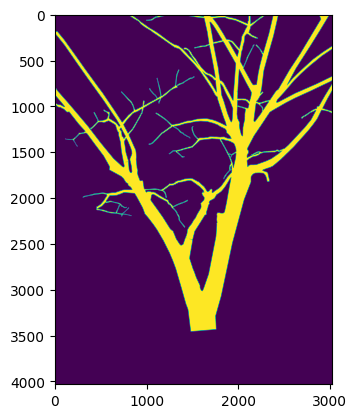

In [2]:
img_orig = cv.imread("resource/branch_dataset/SegmentationClass/Albizia julibrissin_branch_1 (4).png")
img = cv.cvtColor(img_orig, cv.COLOR_RGB2GRAY)
ret, img = cv.threshold(img, 0, 255, cv.THRESH_OTSU)
plt.imshow(img)

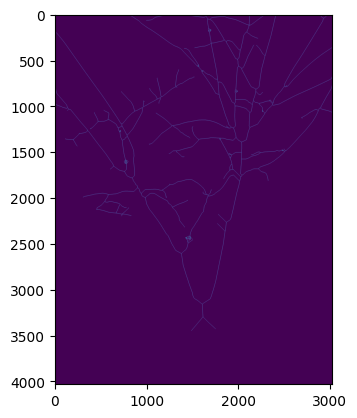

In [3]:
skel = skeletonize(img)
plt.imshow(skel)

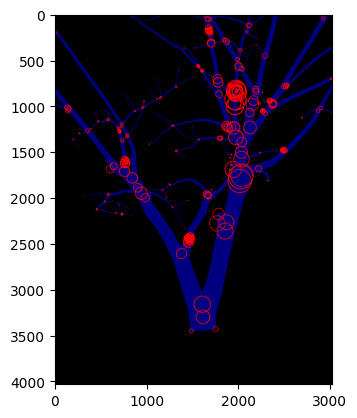

In [4]:
nodes = assemble_nodes(skel, img)
for node in nodes:
    cv.circle(img_orig, (node.pixel_coord[1], node.pixel_coord[0]), node.width//2, color=(255, 0, 0), thickness=5)
plt.imshow(img_orig)

In [9]:
NID = 10
KERNEL = 15
K = KERNEL**2

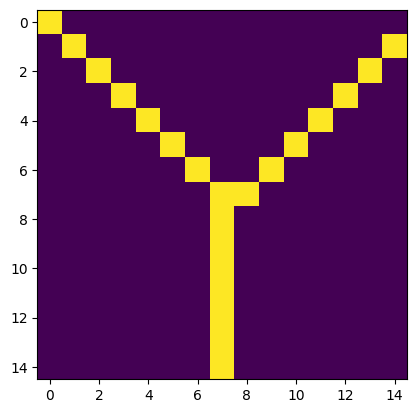

In [10]:
cx = nodes[NID].pixel_coord[1]
cy = nodes[NID].pixel_coord[0]
xmin = cx - (KERNEL//2)
xmax = cx + (KERNEL//2) + 1
ymin = cy - (KERNEL//2) - 1
ymax = cy + (KERNEL//2) 
sub_img = np.zeros((KERNEL, KERNEL))
for x in range(xmin, xmax+1):
    for y in range(ymin, ymax+1):
        try:
            sub_img[y - ymin, x - xmin] = skel[y,x]
        except IndexError:
            pass
plt.imshow(sub_img)

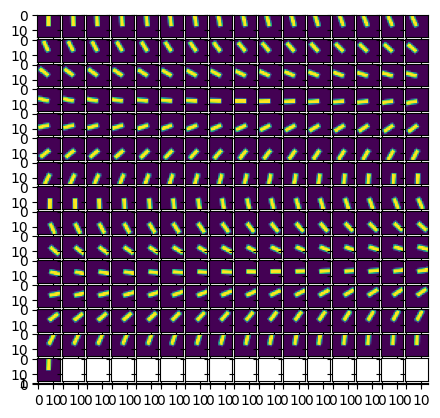

In [11]:
masks = _make_rotating_masks(K, KERNEL)
N = len(masks)
grid = ImageGrid(plt.gcf(), 111, 
                (int(np.sqrt(N)+1),int(np.sqrt(N)+1))
            )
for ax, im in zip(grid, masks):
    ax.imshow(im)

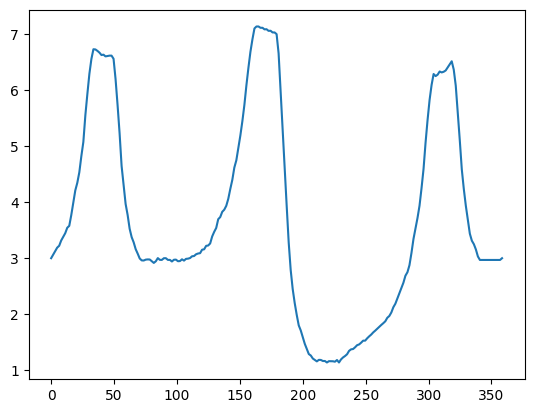

In [12]:
corr = _correlate_angles(sub_img, K, KERNEL)
deg = [i * (360/K) for i in range(len(corr))]
plt.plot(deg, corr)